In [45]:
########################################################################
### Exploratory Analysis for Durham Sensor Network July, August 2024 ###
########################################################################

## Create plots: 
## SVF versus the max daily temperature
## Diurnal cycle split into the 4 categories 

import numpy as np
import pandas as pd
import datetime
from datetime import datetime, timedelta
import os
import pathlib
import matplotlib.pyplot as plt
import matplotlib as mpl
import earthpy as et
import seaborn as sns
from scipy.stats import linregress


hourly_mean_data_path = r'C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Sensor_Network_Output_Data\Sensor_Data_Cleaned\Hourly_Mean_Sensor_Data_July_Aug.csv'

hourly_mean_data = pd.read_csv(hourly_mean_data_path)

hourly_mean_data_incl_rural_path= r'C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Sensor_Network_Output_Data\Sensor_Data_Cleaned\Hourly_Mean_Sensor_Data_July_Aug_incl_rural.csv'

hourly_mean_data_incl_rural = pd.read_csv(hourly_mean_data_incl_rural_path)

# extract the date for averaging 
hourly_mean_data['Date_only'] = pd.to_datetime(hourly_mean_data['Date_Hour_Rounded']).dt.date
hourly_mean_data_incl_rural['Date_only'] = pd.to_datetime(hourly_mean_data_incl_rural['Date_Hour_Rounded']).dt.date
# extract the hour for getting the mean diurnal cycles 
#hourly_mean_data['Hour'] = pd.to_datetime(hourly_mean_data['Date_Hour_Rounded']).dt.strftime('%H:%M')
hourly_mean_data['Hour'] = pd.to_datetime(hourly_mean_data['Date_Hour_Rounded']).dt.hour
hourly_mean_data_incl_rural['Hour'] = pd.to_datetime(hourly_mean_data_incl_rural['Date_Hour_Rounded']).dt.hour

# get the daily average max, min and mean
daily_max_df = hourly_mean_data.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         'Date_only']).max().reset_index().drop(columns ='Date_Hour_Rounded')

daily_min_df = hourly_mean_data.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         'Date_only']).min().reset_index().drop(columns ='Date_Hour_Rounded')

daily_mean_df = hourly_mean_data.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         'Date_only']).mean(numeric_only = True).reset_index()

# Mean monthly daily max summary df
JA_mean_max_df = daily_max_df.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         ]).mean(numeric_only = True).reset_index()
# Mean monthly daily mean summary df
JA_mean_mean_df = daily_mean_df.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         ]).mean(numeric_only = True).reset_index()
# Mean monthly daily min summary df
JA_mean_min_df = daily_min_df.groupby(['Sensor_ID', 'Shade_Type','Landcover_Type','Percent_Vegetation','Lon','Lat','Decile_Group',
                                         ]).mean(numeric_only = True).reset_index()
# Mean monthly hourly summary df 
JA_hourly_mean = hourly_mean_data.groupby(['Shade_Type','Landcover_Type','Hour']).mean(numeric_only = True).reset_index()

Mean SVF Unshaded vegetation 0.5956788951546873
Mean SVF Shaded vegetation 0.1606155879510961
Mean SVF Unshaded impervious 0.7618638019521023
Mean SVF Shaded impervious 0.15464711774656842
Ta r_value: 0.7574493144723793
Ta p value for pearsons r: 2.3812178259381856e-08
Ta r2: 0.5737294639946773
rh r_value: 0.1547754938371898
rh p value for pearsons r: 0.34680184821495674
rh r2: 0.023955453492545978


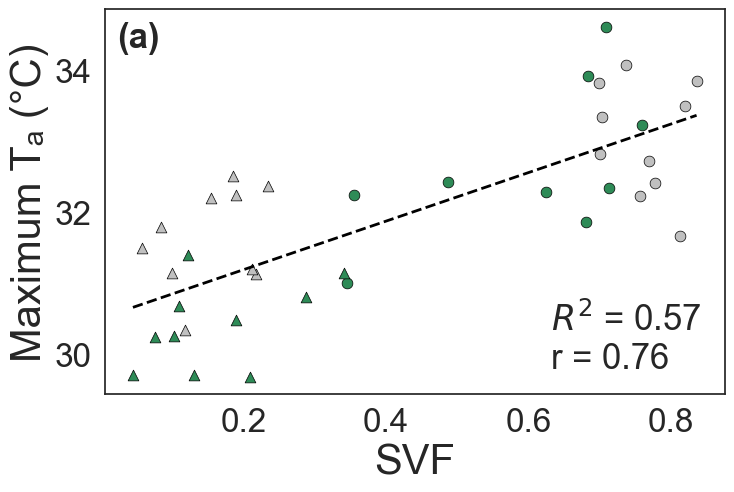

In [44]:
## Plot the mean maximum temperatures and SVF  

landcover_types = ['vegetation','impervious']
shading_types = ['non-shaded','shaded']
sns.set(style="white")
fig, axes = plt.subplots(1,1, figsize = (8,5))

for landcover_type in landcover_types: 
    if landcover_type == 'vegetation':
        color = 'seagreen'
    else:
        color = 'silver'
    
    for shading_type in shading_types:
        if shading_type == 'shaded':
            marker_type = '^'
            shading_label = 'Shaded'
        else:
            marker_type = 'o'
            shading_label = 'Unshaded'
        
        filtered_df = JA_mean_max_df[(JA_mean_max_df['Shade_Type'] ==shading_type)&(
                JA_mean_max_df['Landcover_Type'] == landcover_type) ]

        im = axes.scatter(filtered_df.SVF, filtered_df.Temperature, label = '{} {}'.format(shading_label, landcover_type),
                s = 60, color = color, marker = marker_type, edgecolor='black',linewidth=0.5,)
        
        print(f'Mean SVF {shading_label} {landcover_type}', filtered_df.SVF.mean())
# add a regression line / r2
x_all = JA_mean_max_df['SVF']
y_all = JA_mean_max_df['Temperature']

# Perform linear regression
slope, intercept, r_value, p_value, std_err = linregress(x_all, y_all)
r2 = r_value**2
print('Ta r_value:', r_value)
print('Ta p value for pearsons r:',p_value)
print('Ta r2:', r2)

rh_slope, rh_intercept, rh_r_value, rh_p_value, rh_std_err = linregress(x_all,  JA_mean_max_df['Relative_Humidity'])
rh_r2 = rh_r_value**2
print('rh r_value:', rh_r_value)
print('rh p value for pearsons r:',rh_p_value)
print('rh r2:', rh_r2)

# Plot regression line
x_vals = np.linspace(x_all.min(), x_all.max(), 100)
y_vals = intercept + slope * x_vals
axes.plot(x_vals, y_vals, color='black', linestyle='--', linewidth=2, label='Regression Line')

# Add text with r2 and pearsons r
textstr = (
    f"$R^2$ = {r2:.2f}\n"
   # f"Gradient = {slope:.2f}\n"
    f"r = {r_value:.2f}"
)

axes.text(
    0.72, 0.05, textstr,
    transform=axes.transAxes,
    fontsize=25,
    verticalalignment='bottom',
    horizontalalignment='left',
    #bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='grey')
)

axes.text(
        0.02, 0.97, '(a)',  
        transform=axes.transAxes,
        ha='left', va='top',
        fontsize=25,
        fontweight='bold'
    )
axes.tick_params(axis='both', labelsize=24)
#axes.legend(fontsize = 12, loc = 2, ncol = 1, bbox_to_anchor=(0.08, 1))

#axes.set(title = 'Sky View Factor versus Mean Maximum Daily Temperature', ylabel = 'Mean Daily Maximum Temperature (\u00B0C)', xlabel = 'Sky View Factor')

axes.set_xlabel('SVF', fontsize=30)
axes.set_ylabel('Maximum Tₐ (°C)', fontsize=30)

#os.chdir(os.path.join(et.io.HOME, 'Documents', 'Python_Scripts', 'DDL','Sensor_Network'))
#plt.savefig(r'Plots/svf_mean_max_temp.png', format='png', dpi=1200, bbox_inches='tight')

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\svf_mean_max_temp.png', 
            format='png', dpi=1200, bbox_inches='tight')

rh r_value: 0.7941987474648408
rh p value for pearsons r: 1.5998034962194892e-09
rh r2: 0.6307516504747219
ta r_value: 0.1547754938371898
ta p value for pearsons r: 0.34680184821495674
ta r2: 0.023955453492545978


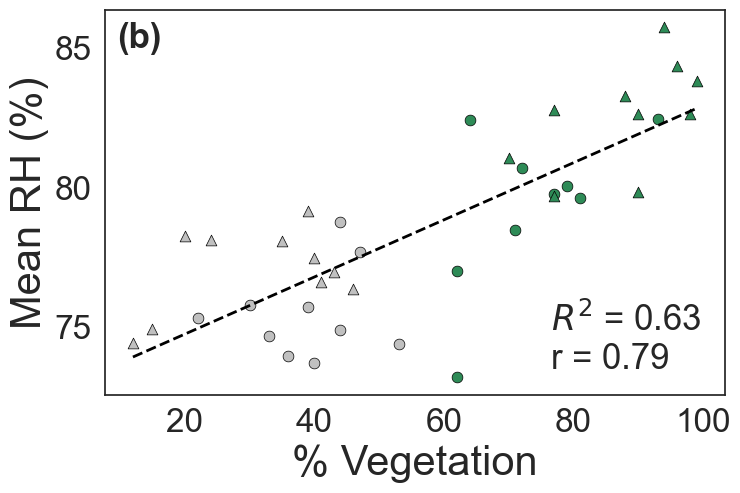

In [45]:
## Plot the mean RH and vegetation %  

landcover_types = ['vegetation','impervious']
shading_types = ['non-shaded','shaded']
sns.set(style="white")
fig, axes = plt.subplots(1,1, figsize = (8,5))

for landcover_type in landcover_types: 
    if landcover_type == 'vegetation':
        color = 'seagreen'
    else:
        color = 'silver'
    
    for shading_type in shading_types:
        if shading_type == 'shaded':
            marker_type = '^'
            shading_label = 'Shaded'
        else:
            marker_type = 'o'
            shading_label = 'Unshaded'
        
        filtered_df = JA_mean_mean_df[(JA_mean_mean_df['Shade_Type'] ==shading_type)&(
                JA_mean_mean_df['Landcover_Type'] == landcover_type) ]

        im = axes.scatter(filtered_df.Percent_Vegetation, filtered_df.Relative_Humidity, label = '{} {}'.format(shading_label, landcover_type),
                s = 60, color = color, marker = marker_type, edgecolor='black',linewidth=0.5,)
        

# add a regression line / r2
x_all = JA_mean_mean_df['Percent_Vegetation']
y_all = JA_mean_mean_df['Relative_Humidity']

# Perform linear regression
slope, intercept, r_value, p_value, std_err = linregress(x_all, y_all)
r2 = r_value**2

print('rh r_value:', r_value)
print('rh p value for pearsons r:',p_value)
print('rh r2:', r2)

ta_slope, ta_intercept, ta_r_value, ta_p_value, ta_std_err = linregress(x_all,  JA_mean_mean_df['Temperature'])
ta_r2 = ta_r_value**2
print('ta r_value:', rh_r_value)
print('ta p value for pearsons r:',rh_p_value)
print('ta r2:', rh_r2)

# Plot regression line
x_vals = np.linspace(x_all.min(), x_all.max(), 100)
y_vals = intercept + slope * x_vals
axes.plot(x_vals, y_vals, color='black', linestyle='--', linewidth=2, label='Regression Line')

# Add text with r2 and pearsons r
textstr = (
    f"$R^2$ = {r2:.2f}\n"
   # f"Gradient = {slope:.2f}\n"
    f"r = {r_value:.2f}"
)

axes.text(
     0.72, 0.05, textstr,
    transform=axes.transAxes,
    fontsize=25,
    verticalalignment='bottom',
    horizontalalignment='left',
   # bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='grey')
)
axes.text(
        0.02, 0.97, '(b)',  
        transform=axes.transAxes,
        ha='left', va='top',
        fontsize=25,
        fontweight='bold'
    )

axes.tick_params(axis='both', labelsize=24)
#axes.legend(fontsize = 12, loc = 2, ncol = 1, bbox_to_anchor=(0.08, 1))

#axes.set(title = 'Percent Vegetation versus Mean Relative Humidity', ylabel = 'Mean Daily Relative Humidity (%)', xlabel = '% Vegetation')

axes.set_xlabel('% Vegetation', fontsize=30)
axes.set_ylabel('Mean RH (%)', fontsize=30)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\rh_veg_percent.png', 
            format='png', dpi=1200, bbox_inches='tight')
#os.chdir(os.path.join(et.io.HOME, 'Documents', 'Python_Scripts', 'DDL','Sensor_Network'))
#plt.savefig(r'Plots/rh_veg_percent.png', format='png', dpi=300, bbox_inches='tight')

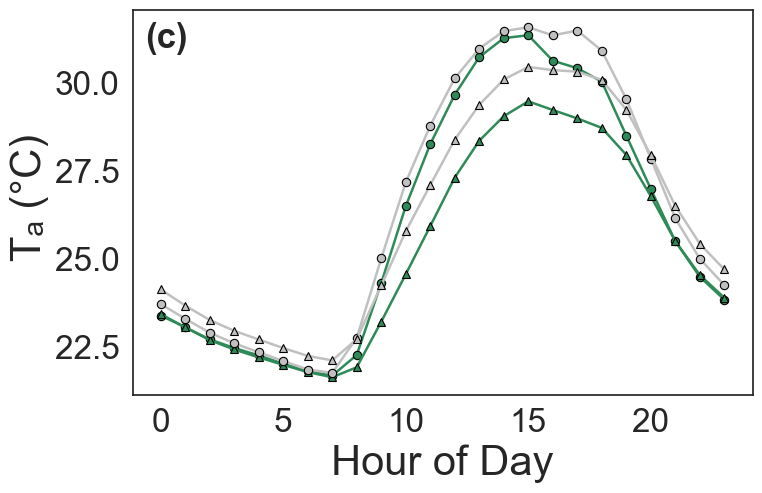

In [31]:
## Plot the mean temperature diurnal cycle 

landcover_types = ['vegetation','impervious']
shading_types = ['non-shaded','shaded']
sns.set(style="white")
fig, axes = plt.subplots(1,1, figsize = (8,5))

for landcover_type in landcover_types: 
    if landcover_type == 'vegetation':
        color = 'seagreen'
    else:
        color = 'silver'
    
    for shading_type in shading_types:
        if shading_type == 'shaded':
            marker_type = '^'
            shading_label = 'Shaded'
        else:
            marker_type = 'o'
            shading_label = 'Unshaded'
        
        filtered_df = JA_hourly_mean[(JA_hourly_mean['Shade_Type'] ==shading_type)&(
                JA_hourly_mean['Landcover_Type'] == landcover_type) ]

        im = axes.plot(filtered_df.Hour, filtered_df.Temperature, label = '{} {}'.format(shading_label, landcover_type),
                color=color,  marker=marker_type,markeredgecolor='black', markeredgewidth=0.8,  linewidth=1.8)
        

#axes.legend(fontsize = 12, loc = 2, ncol = 1, bbox_to_anchor=(0.08, 1))
#plt.xticks(rotation=45)
#axes.set(title = 'Air Temperature Diurnal Cycle', ylabel = 'Air Temperature (\u00B0C)', xlabel = 'Hour')

axes.text(
        0.02, 0.97, '(c)',  
        transform=axes.transAxes,
        ha='left', va='top',
        fontsize=25,
        fontweight='bold'
    )

axes.set_xlabel('Hour of Day', fontsize=30)
axes.set_ylabel('Tₐ (°C)', fontsize=30)

axes.tick_params(axis='both', labelsize=24)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\at_diurnal_cycle.png', 
            format='png', dpi=1200, bbox_inches='tight')
#os.chdir(os.path.join(et.io.HOME, 'Documents', 'Python_Scripts', 'DDL','Sensor_Network'))
#plt.savefig(r'Plots/at_diurnal_cycle.png', format='png', dpi=300, bbox_inches='tight')

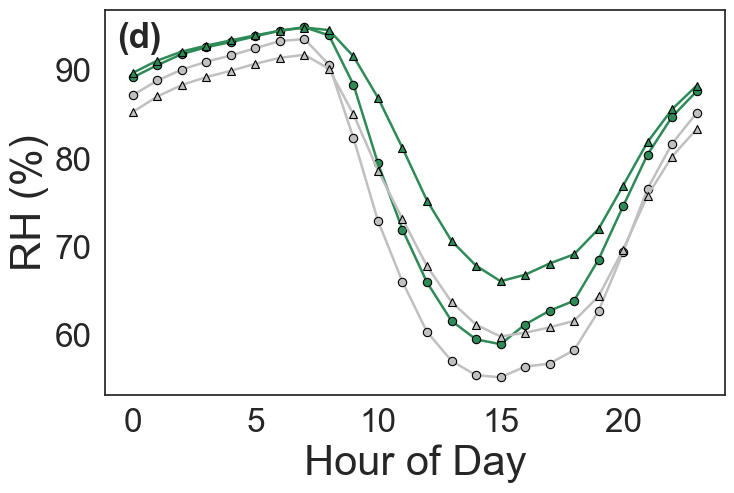

In [33]:
## Plot the mean rh diurnal cycle 

landcover_types = ['vegetation','impervious']
shading_types = ['non-shaded','shaded']
sns.set(style="white")
fig, axes = plt.subplots(1,1, figsize = (8,5))

for landcover_type in landcover_types: 
    if landcover_type == 'vegetation':
        color = 'seagreen'
    else:
        color = 'silver'
    
    for shading_type in shading_types:
        if shading_type == 'shaded':
            marker_type = '^'
            shading_label = 'Shaded'
        else:
            marker_type = 'o'
            shading_label = 'Unshaded'
        
        filtered_df = JA_hourly_mean[(JA_hourly_mean['Shade_Type'] ==shading_type)&(
                JA_hourly_mean['Landcover_Type'] == landcover_type) ]

        im = axes.plot(filtered_df.Hour, filtered_df.Relative_Humidity, label = '{} {}'.format(shading_label, landcover_type),
                color=color,  marker=marker_type,markeredgecolor='black', markeredgewidth=0.8,  linewidth=1.8)
        
#axes.legend(fontsize = 12, loc = 3, ncol = 1)
#plt.xticks(rotation=45)
#axes.set(title = 'Relative Humidity Diurnal Cycle', ylabel = 'Relative Humidity (%)', xlabel = 'Hour')
axes.text(
        0.02, 0.97, '(d)',  
        transform=axes.transAxes,
        ha='left', va='top',
        fontsize=25,
        fontweight='bold'
    )
axes.set_xlabel('Hour of Day', fontsize=30)
axes.set_ylabel('RH (%)', fontsize=30)

axes.tick_params(axis='both', labelsize=24)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\rh_diurnal_cycle.png', 
            format='png', dpi=1200, bbox_inches='tight')

#os.chdir(os.path.join(et.io.HOME, 'Documents', 'Python_Scripts', 'DDL','Sensor_Network'))
#plt.savefig(r'Plots/rh_diurnal_cycle.png', format='png', dpi=300, bbox_inches='tight')

In [76]:
#Extracting numbers on the differences 
# by landcover 
print('Impervious - Vegetated Differences')
#ta
hourly_mean_impervious = JA_hourly_mean[JA_hourly_mean['Landcover_Type'] == 'impervious'].groupby('Hour').Temperature.mean()
hourly_mean_vegetation = JA_hourly_mean[JA_hourly_mean['Landcover_Type'] == 'vegetation'].groupby('Hour').Temperature.mean()

mean_diffs = hourly_mean_impervious - hourly_mean_vegetation

print('08:00 - 19:00 Ta diff', mean_diffs[(mean_diffs.index >= 8)&(mean_diffs.index <= 19)].mean())
print('20:00 - 07:00 Ta diff', mean_diffs[(mean_diffs.index <= 7)|(mean_diffs.index >= 20)].mean())

#rh
hourly_mean_impervious = JA_hourly_mean[JA_hourly_mean['Landcover_Type'] == 'impervious'].groupby('Hour').Relative_Humidity.mean()
hourly_mean_vegetation = JA_hourly_mean[JA_hourly_mean['Landcover_Type'] == 'vegetation'].groupby('Hour').Relative_Humidity.mean()

mean_diffs = hourly_mean_impervious - hourly_mean_vegetation

print('08:00 - 19:00 RH diff', mean_diffs[(mean_diffs.index >= 8)&(mean_diffs.index <= 19)].mean())
print('20:00 - 07:00 RH diff', mean_diffs[(mean_diffs.index <= 7)|(mean_diffs.index >= 20)].mean())



print('Shaded Vegetated')
#ta
hourly_mean_vegetation_shaded = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                               )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Temperature.mean()

print('08:00 - 19:00 Ta mean', 
      hourly_mean_vegetation_shaded[(hourly_mean_vegetation_shaded.index >= 8)&(hourly_mean_vegetation_shaded.index <= 19)].mean())

print('20:00 - 07:00 Ta mean', 
      hourly_mean_vegetation_shaded[(hourly_mean_vegetation_shaded.index <= 7)|(hourly_mean_vegetation_shaded.index >= 20)].mean())

#rh
hourly_mean_vegetation_shaded = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                               )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Relative_Humidity.mean()

print('08:00 - 19:00 RH mean', 
      hourly_mean_vegetation_shaded[(hourly_mean_vegetation_shaded.index >= 8)&(hourly_mean_vegetation_shaded.index <= 19)].mean())

print('20:00 - 07:00 RH mean', 
      hourly_mean_vegetation_shaded[(hourly_mean_vegetation_shaded.index <= 7)|(hourly_mean_vegetation_shaded.index >= 20)].mean())


print('Unshaded impervious')
#ta
hourly_mean_impervious_unshaded = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                               )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Temperature.mean()

print('08:00 - 19:00 Ta mean', 
      hourly_mean_impervious_unshaded[(hourly_mean_impervious_unshaded.index >= 8)&(hourly_mean_impervious_unshaded.index <= 19)].mean())

print('20:00 - 07:00 Ta mean', 
      hourly_mean_impervious_unshaded[(hourly_mean_impervious_unshaded.index <= 7)|(hourly_mean_impervious_unshaded.index >= 20)].mean())

#rh
hourly_mean_impervious_unshaded = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                               )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Relative_Humidity.mean()

print('08:00 - 19:00 RH mean', 
      hourly_mean_impervious_unshaded[(hourly_mean_impervious_unshaded.index >= 8)&(hourly_mean_impervious_unshaded.index <= 19)].mean())

print('20:00 - 07:00 RH mean', 
      hourly_mean_impervious_unshaded[(hourly_mean_impervious_unshaded.index <= 7)|(hourly_mean_impervious_unshaded.index >= 20)].mean())


Impervious - Vegetated Differences
08:00 - 19:00 Ta diff 0.8606232211597845
20:00 - 07:00 Ta diff 0.4927533087563554
08:00 - 19:00 RH diff -6.063504681068976
20:00 - 07:00 RH diff -3.3074917100276457
Shaded Vegetated
08:00 - 19:00 Ta mean 27.05256443014345
20:00 - 07:00 Ta mean 23.32338321546942
08:00 - 19:00 RH mean 75.83785928864478
20:00 - 07:00 RH mean 89.57887238058014
Unshaded impervious
08:00 - 19:00 Ta mean 29.255757492749414
20:00 - 07:00 Ta mean 23.648727211628838
All hours Ta mean 26.45224235218913
08:00 - 19:00 RH mean 64.50291321836114
20:00 - 07:00 RH mean 86.7372345142258
All hours RH mean 75.62007386629348


In [82]:
## shaded impervious 
#ta
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Temperature.mean()

print('shaded impervious 08:00 - 19:00 Ta mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())
#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Relative_Humidity.mean()

print('shaded impervious 08:00 - 19:00 RH mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())


## shaded vegetation 
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Temperature.mean()

print('shaded vegetated 08:00 - 19:00 Ta mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Relative_Humidity.mean()

print('shaded vegetated 08:00 - 19:00 RH mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

## unshaded 
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Temperature.mean()

print('unshaded impervious 08:00 - 19:00 Ta mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Relative_Humidity.mean()

print('unshaded impervious 08:00 - 19:00 RH mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Temperature.mean()

print('unshaded vegetated 08:00 - 19:00 Ta mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Relative_Humidity.mean()

print('unshaded vegetated 08:00 - 19:00 RH mean', 
      df[(df.index >= 8)&(df.index <= 19)].mean())

shaded impervious 08:00 - 19:00 Ta mean 28.172033774099017
shaded impervious 08:00 - 19:00 RH mean 68.87485825181793
shaded vegetated 08:00 - 19:00 Ta mean 27.05256443014345
shaded vegetated 08:00 - 19:00 RH mean 75.83785928864478
unshaded impervious 08:00 - 19:00 Ta mean 29.255757492749414
unshaded impervious 08:00 - 19:00 RH mean 64.50291321836114
unshaded vegetated 08:00 - 19:00 Ta mean 28.653980394385414
unshaded vegetated 08:00 - 19:00 RH mean 69.66692154367225


In [83]:
## Night

## shaded impervious 
#ta
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Temperature.mean()

print('shaded impervious 21:00 - 07:00 Ta mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())
#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Relative_Humidity.mean()

print('shaded impervious 21:00 - 07:00 RH mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())


## shaded vegetation 
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Temperature.mean()

print('shaded vegetated 21:00 - 07:00 Ta mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'shaded')].groupby('Hour').Relative_Humidity.mean()

print('shaded vegetated 21:00 - 07:00 RH mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

## unshaded 
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Temperature.mean()

print('unshaded impervious 21:00 - 07:00 Ta mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Relative_Humidity.mean()

print('unshaded impervious 21:00 - 07:00 RH mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Temperature.mean()

print('unshaded vegetated 21:00 - 07:00 Ta mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

#rh
df = JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation'
                                )&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].groupby('Hour').Relative_Humidity.mean()

print('unshaded vegetated 21:00 - 07:00 RH mean', 
      df[(df.index <= 7)|(df.index >= 20)].mean())

shaded impervious 21:00 - 07:00 Ta mean 24.006370001843806
shaded impervious 21:00 - 07:00 RH mean 85.22287700287546
shaded vegetated 21:00 - 07:00 Ta mean 23.32338321546942
shaded vegetated 21:00 - 07:00 RH mean 89.57887238058014
unshaded impervious 21:00 - 07:00 Ta mean 23.648727211628838
unshaded impervious 21:00 - 07:00 RH mean 86.7372345142258
unshaded vegetated 21:00 - 07:00 Ta mean 23.34620738049051
unshaded vegetated 21:00 - 07:00 RH mean 88.99622255657646


In [80]:
# Ta

print("Mean Ta vegetated shaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation')&(JA_hourly_mean['Shade_Type'] == 'shaded')].Temperature.mean())

print("Mean Ta vegetated unshaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation')&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].Temperature.mean())

print("Mean Ta impervious shaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious')&(JA_hourly_mean['Shade_Type'] == 'shaded')].Temperature.mean())

print("Mean Ta impervious unshaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious')&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].Temperature.mean())


## RH

print("Mean RH vegetated shaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation')&(JA_hourly_mean['Shade_Type'] == 'shaded')].Relative_Humidity.mean())

print("Mean RH vegetated unshaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'vegetation')&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].Relative_Humidity.mean())

print("Mean RH impervious shaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious')&(JA_hourly_mean['Shade_Type'] == 'shaded')].Relative_Humidity.mean())

print("Mean RH impervious unshaded",
JA_hourly_mean[(JA_hourly_mean['Landcover_Type'] == 'impervious')&(JA_hourly_mean['Shade_Type'] == 'non-shaded')].Relative_Humidity.mean())



Mean Ta vegetated shaded 25.18797382280643
Mean Ta vegetated unshaded 26.000093887437966
Mean Ta impervious shaded 26.08920188797141
Mean Ta impervious unshaded 26.45224235218913
Mean RH vegetated shaded 82.70836583461245
Mean RH vegetated unshaded 79.33157205012436
Mean RH impervious shaded 77.0488676273467
Mean RH impervious unshaded 75.62007386629348


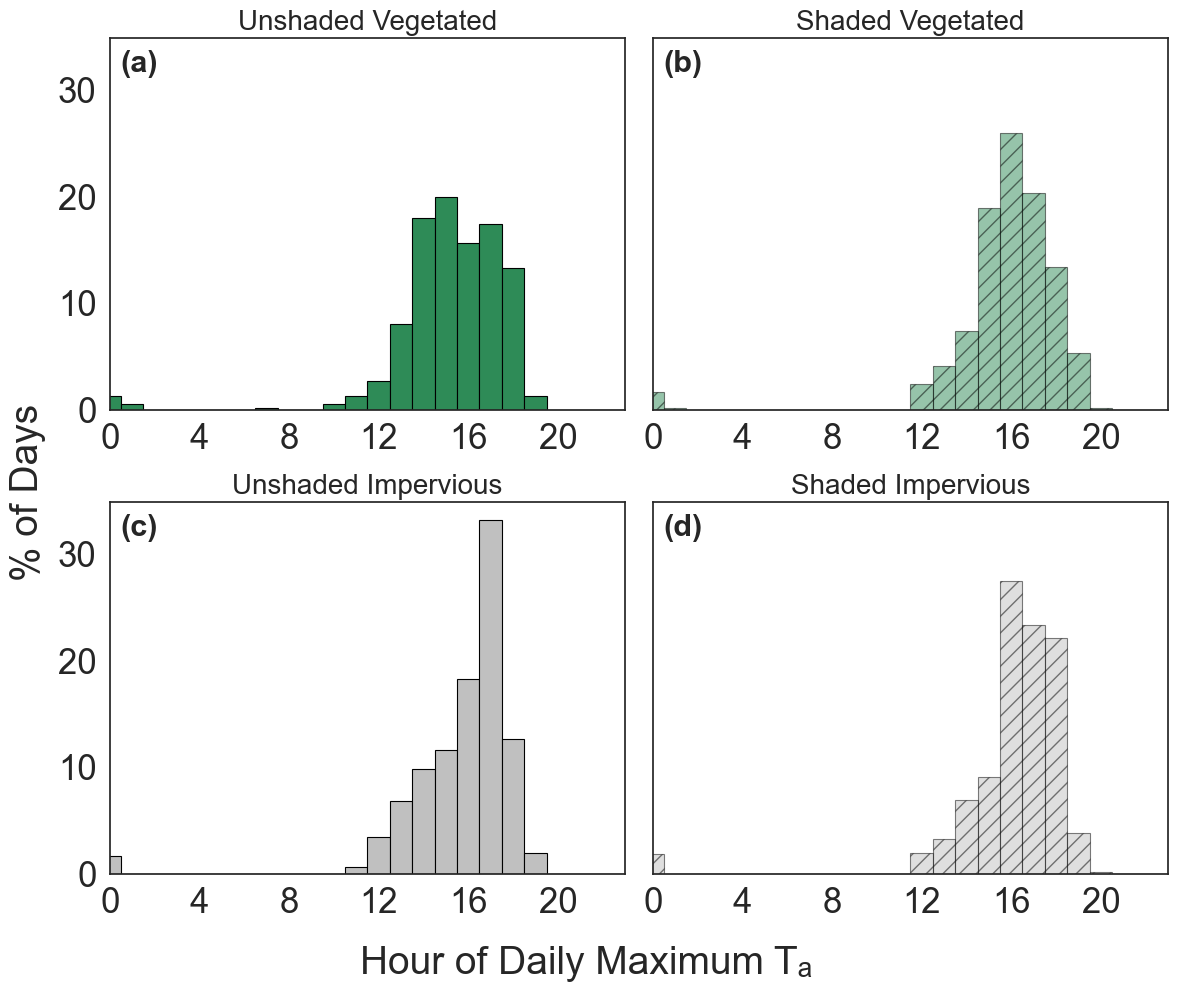

In [27]:
## Plot distribution of peak temperature hour for each sensor category

import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


# find hour of daily peak temperature for each sensor

peak_idx = (
    hourly_mean_data
    .groupby(['Sensor_ID', 'Date_only'])['Temperature']
    .idxmax()
)

peak_data = hourly_mean_data.loc[peak_idx].copy()


# Plot

landcover_types = ['vegetation', 'impervious']
shading_types = ['non-shaded', 'shaded']

sns.set(style="white")

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

axes = axes.flatten()

plot_num = 0

for landcover_type in landcover_types:

    if landcover_type == 'vegetation':
        color = 'seagreen'
        landcover_label = 'Vegetated'
    else:
        color = 'silver'
        landcover_label = 'Impervious'

    for shading_type in shading_types:

        ax = axes[plot_num]

        if shading_type == 'shaded':
            shading_label = 'Shaded'
            alpha_val = 0.5
            hatch_pattern = '//'
        else:
            shading_label = 'Unshaded'
            alpha_val = 1
            hatch_pattern = None
            
        # filter data
        filtered_df = peak_data[
            (peak_data['Shade_Type'] == shading_type) &
            (peak_data['Landcover_Type'] == landcover_type)
        ]
        
        # get the percentages 
        weights = np.ones(len(filtered_df)) / len(filtered_df) * 100
        # histogram of peak hour occurrence
        ax.hist(
            filtered_df['Hour'],
            bins=np.arange(-0.5, 24.5, 1),
            weights=weights,
            density=False,
            color=color,
            edgecolor='black',
            linewidth=0.8,
            alpha=alpha_val,
            hatch=hatch_pattern
        )

        # formatting
        ax.set_title(
            f'{shading_label} {landcover_label}',
            fontsize=20
        )

        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 4))

        ax.tick_params(axis='both', labelsize=25)

        # panel labels
        subplot_labels = ['(a)', '(b)', '(c)', '(d)']

        ax.text(
            0.02, 0.97,
            subplot_labels[plot_num],
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=22,
            fontweight='bold'
        )

        plot_num += 1

# shared labels
fig.supxlabel('Hour of Daily Maximum Tₐ', fontsize=28)
fig.supylabel('% of Days', fontsize=28)

plt.tight_layout()

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\peak_temperature_hour_distribution.png',
    format='png', dpi=1200, bbox_inches='tight')


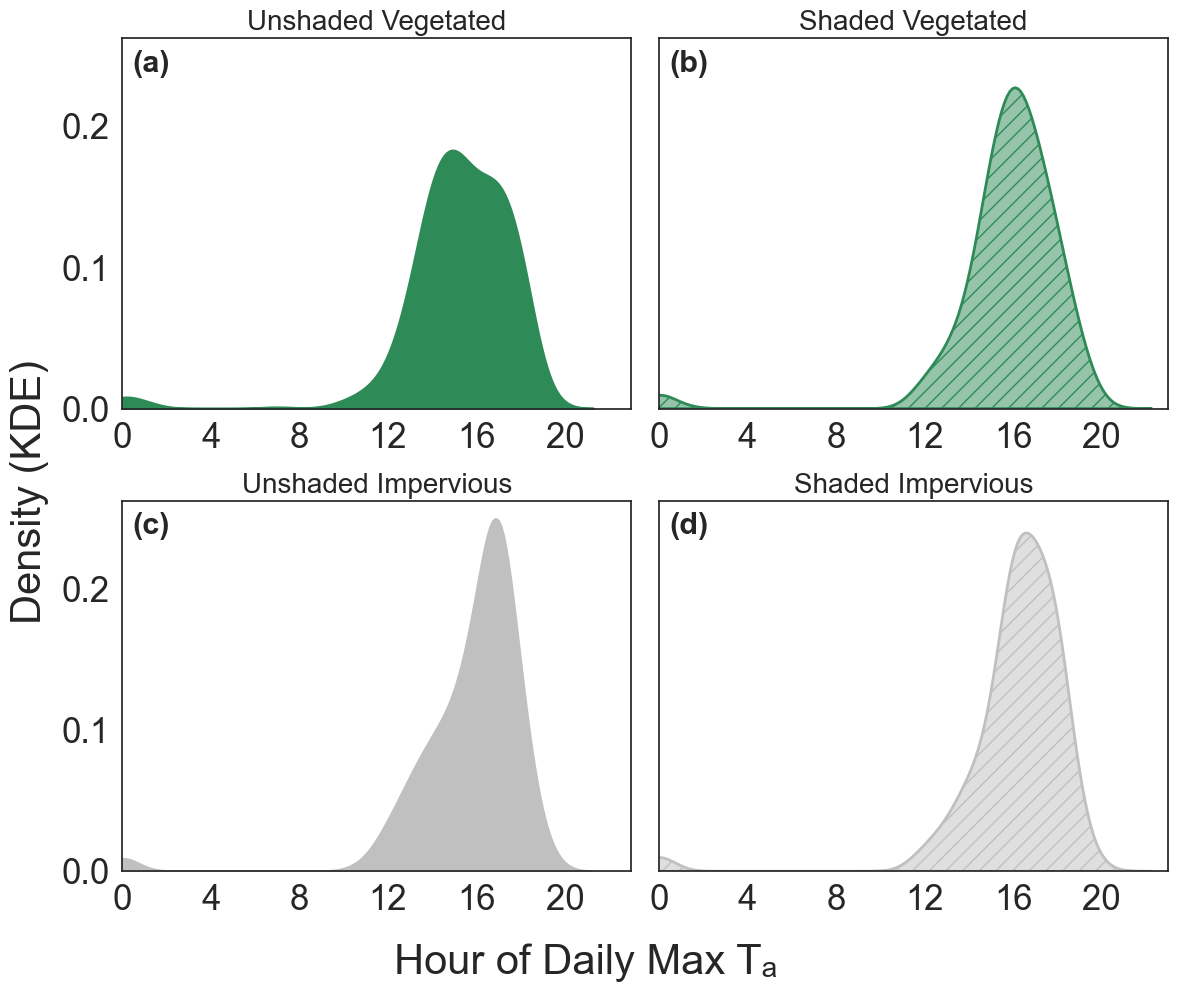

In [26]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Find hour of daily peak temperature for each sensor
peak_idx = (
    hourly_mean_data
    .groupby(['Sensor_ID', 'Date_only'])['Temperature']
    .idxmax()
)

peak_data = hourly_mean_data.loc[peak_idx].copy()

#plot the 

landcover_types = ['vegetation', 'impervious']
shading_types = ['non-shaded', 'shaded']

sns.set(style="white")

fig, axes = plt.subplots(2, 2, figsize=(12, 10),  sharey=True)
axes = axes.flatten()

plot_num = 0

for landcover_type in landcover_types:

    if landcover_type == 'vegetation':
        color = 'seagreen'
        landcover_label = 'Vegetated'
    else:
        color = 'silver'
        landcover_label = 'Impervious'

    for shading_type in shading_types:

        ax = axes[plot_num]

        if shading_type == 'shaded':
            shading_label = 'Shaded'
            alpha_val = 0.5
            hatch_pattern = '//'
        else:
            shading_label = 'Unshaded'
            alpha_val = 1
            hatch_pattern = None

        filtered_df = peak_data[(peak_data['Shade_Type'] == shading_type) &  (peak_data['Landcover_Type'] == landcover_type)]

        # KDE instead of histogram

        sns.kdeplot(
            data=filtered_df,
            x='Hour',
            ax=ax,
            color=color,
            linewidth=2,
            fill=True,          
            alpha=alpha_val,
            bw_adjust=1.0,       
            hatch=hatch_pattern)

        # formatting
        ax.set_title(f'{shading_label} {landcover_label}', fontsize=20)

        ax.set_xlim(0, 23)
        ax.set_xticks(range(0, 24, 4))

        ax.tick_params(axis='both', labelsize=25)
        
        ax.set_xlabel('') # remove default labels 
        ax.set_ylabel('')
        
        
        subplot_labels = ['(a)', '(b)', '(c)', '(d)']

        ax.text(
            0.02, 0.97,
            subplot_labels[plot_num],
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=22,
            fontweight='bold'
        )

        plot_num += 1

# shared labels
fig.supxlabel('Hour of Daily Max Tₐ', fontsize=30)
fig.supylabel('Density (KDE)', fontsize=30)

plt.tight_layout()

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\peak_temperature_kde.png',
        dpi=1200,bbox_inches='tight')

In [47]:
hourly_mean_data_rural_sensor = hourly_mean_data_incl_rural[hourly_mean_data_incl_rural.Sensor_ID == 2968901]

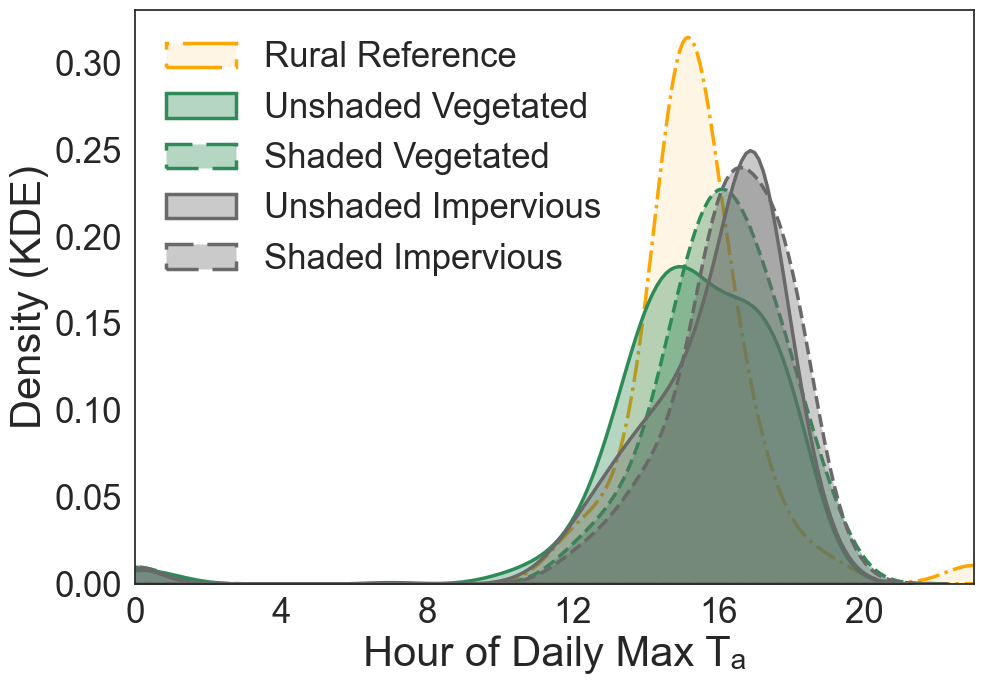

In [52]:
# All KDE plots on a single axes 


# find hour of daily peak temperature for each sensor
peak_idx = (hourly_mean_data .groupby(['Sensor_ID', 'Date_only'])['Temperature'].idxmax())

peak_data = hourly_mean_data.loc[peak_idx].copy()


# for the rural reference sensor
peak_idx_rural_sensor = (hourly_mean_data_rural_sensor.groupby(['Sensor_ID', 'Date_only'])['Temperature'].idxmax())

peak_data_rural_sensor = hourly_mean_data_rural_sensor.loc[peak_idx_rural_sensor].copy()

landcover_types = ['vegetation', 'impervious']
shading_types = ['non-shaded', 'shaded']

sns.set(style="white")

fig, ax = plt.subplots(figsize=(10, 7))


# add the rural reference sensor first
label = "Rural Reference"
sns.kdeplot(data=peak_data_rural_sensor, x='Hour',ax=ax,color="orange",linewidth=2.5,linestyle='-.',fill=True,
            alpha=0.1,bw_adjust=1.0, label=label)



for landcover_type in landcover_types:

    if landcover_type == 'vegetation':
        color = 'seagreen'
        landcover_label = 'Vegetated'
    else:
        color = 'dimgray'
        landcover_label = 'Impervious'

    for shading_type in shading_types:

        if shading_type == 'shaded':
            shading_label = 'Shaded'
            linestyle = '--'
            alpha_val = 0.35
        else:
            shading_label = 'Unshaded'
            linestyle = '-'
            alpha_val = 0.35

        filtered_df = peak_data[
            (peak_data['Shade_Type'] == shading_type) &
            (peak_data['Landcover_Type'] == landcover_type)
        ]

        # label for legend
        label = f'{shading_label} {landcover_label}'

        sns.kdeplot(
            data=filtered_df,
            x='Hour',
            ax=ax,
            color=color,
            linewidth=2.5,
            linestyle=linestyle,
            fill=True,
            alpha=alpha_val,
            bw_adjust=1.0,
            label=label
        )



ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 4))

ax.tick_params(axis='both', labelsize=25)

ax.set_xlabel('Hour of Daily Max Tₐ', fontsize=30)
ax.set_ylabel('Density (KDE)', fontsize=30)

ax.legend(fontsize=25, frameon=False)

plt.tight_layout()

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\peak_temperature_kde_combined.png',
    dpi=1200, bbox_inches='tight')
